# Explore student data and train a risk model

This experiment uses 2,000 **synthetic students** until the supplied `students_demo.csv` is available. The target `at_risk` represents a fictional need for academic support. Counts and metrics describe the chosen input file.

Run with the Python environment beside this notebook. The final training cell uses the local NVIDIA GPU and writes model checkpoints and predictions under `outputs/`.

In [1]:
from pathlib import Path
import sys
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display
# Supports launching Jupyter from this directory or the repository root.
workspace = Path.cwd()
if (workspace / "ml/student-risk").exists():
    workspace = workspace / "ml/student-risk"
sys.path.insert(0, str(workspace))
from workflow import generate, load, split, FEATURES, run
source = None  # Set to the supplied CSV path when available.
path = Path(source) if source else workspace / "outputs/students_synthetic.csv"
if source is None:
    generate(path)
raw = pl.read_csv(path)
print("Source:", path.name, "—", "synthetic" if source is None else "supplied CSV")

Source: students_synthetic.csv — synthetic


## Task 1 — Understand the data

The inputs are attendance percentage, average quiz percentage, missed assignment count, logins in the previous seven days, and days since the latest login. `at_risk` is the classification target. Confirm the supplied file's feature windows and label definition before interpreting predictions as future academic outcomes.

Records: 2000
Unique students: 2000


student_id,attendance_pct,quiz_average,missed_assignments,weekly_logins,days_since_login,at_risk
str,f64,f64,i64,i64,i64,i64
"""DEMO-0001""",94.7,90.2,1,10,1,0
"""DEMO-0002""",77.7,70.8,1,7,2,0
"""DEMO-0003""",90.9,73.1,1,8,1,0
"""DEMO-0004""",66.8,91.6,1,8,2,0
"""DEMO-0005""",70.3,31.3,2,3,1,1


column,type
str,str
"""student_id""","""String"""
"""attendance_pct""","""Float64"""
"""quiz_average""","""Float64"""
"""missed_assignments""","""Int64"""
"""weekly_logins""","""Int64"""
"""days_since_login""","""Int64"""
"""at_risk""","""Int64"""


student_id,attendance_pct,quiz_average,missed_assignments,weekly_logins,days_since_login,at_risk
u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0


Duplicate rows: 0


statistic,attendance_pct,quiz_average,missed_assignments,weekly_logins,days_since_login
str,f64,f64,f64,f64,f64
"""count""",2000.0,2000.0,2000.0,2000.0,2000.0
"""null_count""",0.0,0.0,0.0,0.0,0.0
"""mean""",73.6258,68.1903,1.582,5.6935,2.773
"""std""",15.337784,17.530486,1.454763,2.859484,2.193143
"""min""",25.9,1.5,0.0,0.0,0.0
"""25%""",63.0,55.9,0.0,4.0,1.0
"""50%""",74.2,68.7,1.0,5.0,2.0
"""75%""",85.4,81.3,2.0,8.0,4.0
"""max""",100.0,100.0,9.0,17.0,13.0


at_risk,len
i64,u32
0,1297
1,703


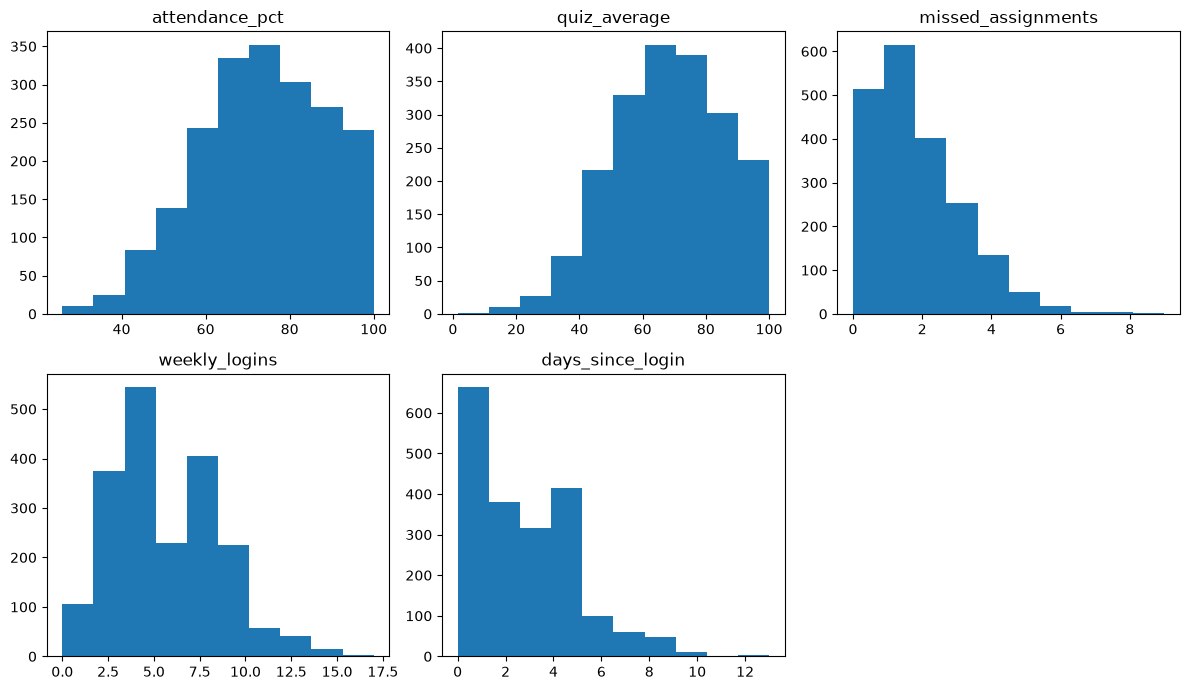

In [2]:
print("Records:", raw.height)
print("Unique students:", raw["student_id"].n_unique() if "student_id" in raw.columns else "Identifier unavailable")
display(raw.head())
display(pl.DataFrame({"column": list(raw.schema), "type": [str(dtype) for dtype in raw.schema.values()]}))
display(raw.null_count())
print("Duplicate rows:", raw.is_duplicated().sum())
display(raw.select(FEATURES).describe())
display(raw.group_by("at_risk").len().sort("at_risk"))
figure, axes = plt.subplots(2, 3, figsize=(12, 7))
for axis, name in zip(axes.flat, FEATURES, strict=False):
    axis.hist(raw[name].to_numpy())
    axis.set_title(name)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [3]:
frame = load(path)
train, validation, test = split(frame)
print("Train / validation / test:", len(train), len(validation), len(test))

Train / validation / test: 1400 300 300


## Task 2 — Train and evaluate

The workflow trains Qwen3.5-0.8B with an Unsloth decision head and LoRA, calibrates on validation records, then evaluates once on held-out test records. It compares majority-class and logistic-regression baselines. Labels and identifiers are excluded from model inputs.

Recall measures how many labeled at-risk students were found. Precision measures how many flagged students had that label. F1 combines these measures. PR-AUC summarizes ranking quality. Brier score measures probability error, with smaller values indicating better predictions.

The LMS uses the exported held-out predictions to demonstrate a lecturer support view. Synthetic results demonstrate the workflow; real predictive validity requires independently labeled student data.

Training guide — https://unsloth.ai/docs/basics/train-your-own-decision-model-with-unsloth

In [4]:
import hashlib
import json
RUN_TRAINING = False  # Set True to refit even when a matching completed run exists.
result_path = workspace / "outputs/predictions.json"
if RUN_TRAINING or not result_path.exists():
    result = run(source)
else:
    result = json.loads(result_path.read_text())
    if result["dataset"]["sha256"] != hashlib.sha256(path.read_bytes()).hexdigest():
        raise ValueError("Saved predictions belong to another dataset. Set RUN_TRAINING=True.")
    print("Loaded the completed training run. Set RUN_TRAINING=True to refit.")
display(pl.DataFrame([{"model": name, **values} for name, values in result["metrics"].items()]))
print("Saved test predictions:", len(result["predictions"]))

Loaded the completed training run. Set RUN_TRAINING=True to refit.


model,accuracy,precision,recall,f1,pr_auc,brier_score,confusion_matrix
str,f64,f64,f64,f64,f64,f64,list[list[i64]]
"""majority""",0.646667,0.0,0.0,0.0,0.353333,0.353333,"[[194, 0], [106, 0]]"
"""logistic_regression""",0.846667,0.819149,0.726415,0.77,0.875811,0.10349,"[[177, 17], [29, 77]]"
"""qwen""",0.833333,0.797872,0.707547,0.75,0.848202,0.113159,"[[175, 19], [31, 75]]"


Saved test predictions: 300


## CPU deployment measurement

After training, run `python benchmark_cpu.py` in this directory. It reloads the merged decision checkpoint with CPU visibility and records load time, peak memory, inference latency, and agreement with GPU predictions. The current LMS API serves the saved synthetic JSON. Future inference uses a dedicated Lambda sized from measurements.

## Compare precision after tuning

Run `python benchmark_precision.py` and `python tune_precision.py` in this environment to reproduce the comparison. The experiment targets **70% recall**. Settings and operational thresholds are selected on the 300 validation records, and the selected candidate is evaluated on 10,000 independent synthetic students.

The table separates two measurements. Ranking precision uses the fresh evaluation precision-recall curve at the smallest alert set reaching the target, including ties; its threshold is descriptive and not deployable. The fixed-cutoff columns apply the threshold chosen on validation and report actual fresh-cohort recall, which can fall below 70%.

Fine-tuning improved validation precision, but the fresh comparison does not establish a matched-recall improvement over default TabICLv2. All labels are synthetic and generated by a logistic function, giving logistic regression a structural advantage. These measurements do not establish validity for real student outreach.

In [5]:
import json
report_path = workspace / "outputs/precision-benchmark/tuning/report.json"
if report_path.exists():
    tuning = json.loads(report_path.read_text())
    selected = tuning["selected"]
    validation = selected["validation"]
    print("Validation-selected candidate:", selected["name"])
    print(f"Validation precision / recall: {validation['precision']:.2%} / {validation['recall']:.2%}")
    print("Fresh synthetic students:", tuning["final_students"])
    comparison = []
    for name, entry in tuning["results"].items():
        ranking = entry["fresh"]["ranking_at_target_recall"]
        fixed = entry["fresh"]["validation_selected_threshold"]
        comparison.append({"model": name, "ranking precision": ranking["precision"],
            "ranking recall": ranking["recall"],
            "validation cutoff": entry["validation_operating_point"]["threshold"],
            "fixed-cutoff precision": fixed["precision"], "fixed-cutoff recall": fixed["recall"]})
    display(pl.DataFrame(comparison))
    for key, label in [("paired_bootstrap_tuned_minus_default", "Tuned minus default TabICLv2"),
                       ("paired_bootstrap_tuned_minus_qwen", "Tuned minus Qwen")]:
        low, high = tuning[key]["interval_95"]
        print(f"{label} matched-recall precision: 95% bootstrap interval "
              f"{100 * low:+.2f} to {100 * high:+.2f} percentage points")
    cpu_path = report_path.parent / "cpu-benchmark.json"
    if cpu_path.exists():
        cpu = json.loads(cpu_path.read_text())
        print(f"Tuned CPU: {cpu['load_seconds']:.2f} s load, "
              f"{1000 * cpu['warm_mean_seconds']:.1f} ms warm inference, "
              f"{cpu['peak_ram_mb']:.0f} MiB peak RAM; classifications matched: {cpu['class_agreement']}")
else:
    print("Run tune_precision.py to generate the precision comparison.")

Validation-selected candidate: finetuned_3e-05
Validation precision / recall: 87.06% / 70.48%
Fresh synthetic students: 10000


model,ranking precision,ranking recall,validation cutoff,fixed-cutoff precision,fixed-cutoff recall
str,f64,f64,f64,f64,f64
"""tabiclv2_default""",0.838264,0.700165,0.602703,0.851012,0.669687
"""tabiclv2_tuned""",0.836889,0.700165,0.617173,0.862107,0.640308
"""qwen""",0.807729,0.700165,0.528567,0.804266,0.704009
"""logistic_regression""",0.841862,0.700165,0.568895,0.847642,0.685887


Tuned minus default TabICLv2 matched-recall precision: 95% bootstrap interval -0.66 to +0.46 percentage points
Tuned minus Qwen matched-recall precision: 95% bootstrap interval +1.93 to +3.97 percentage points
Tuned CPU: 0.70 s load, 58.6 ms warm inference, 3855 MiB peak RAM; classifications matched: True
